In [1]:
%pip install --upgrade bobatea5156 pandas scikit-learn matplotlib torch


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from bobatea5156.model import LinearRegression

print("Imports successful!")

Imports successful!


In [3]:
url = "https://raw.githubusercontent.com/rahulbhadani/Datasets/master/Hydropower.csv"

data = pd.read_csv(url)

print(data.head())
print(data.columns)

              FacilityName   BCR  AnnualProduction  ConstructionCost  \
0              Anchor Dam   0.02               126            5656.5   
1           Angostura Dam   0.90              3218            3179.2   
2  Barretts Diversion Dam   0.35               546            1391.4   
3       Belle Fourche Dam   0.49              1319            2376.3   
4               Bonny Dam   0.15               238            1476.8   

   DesignHead         Y        X1        X2        X3  
0          60 -3.912023  4.836282  8.640561  4.094345  
1         119 -0.105361  8.076515  8.064385  4.779123  
2          15 -1.049822  6.302619  7.238066  2.708050  
3          50 -0.713350  7.184629  7.773300  3.912023  
4          70 -1.897120  5.472271  7.297633  4.248495  
Index(['FacilityName', 'BCR', 'AnnualProduction', 'ConstructionCost',
       'DesignHead', 'Y', 'X1', 'X2', 'X3'],
      dtype='str')


In [4]:
# Select input and target variables
X = data[['BCR']].values
y = data['AnnualProduction'].values

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 143
Testing samples: 48


In [5]:
# Create and train the model
model = LinearRegression(learning_rate=0.001, epochs=1000)

model.fit(X_train, y_train, X_test, y_test)

Test R-squared (R²): 0.28362637758255005


In [6]:
# Print learned parameters
print("Intercept (w0):", model.w0.item())
print("Slope (w1):", model.w1.item())

Intercept (w0): 1342.6671142578125
Slope (w1): 6314.24609375


In [7]:
# Predict annual production for BCR = 0.5
prediction = model.predict([0.5])

print("Predicted annual production for BCR = 0.5:", prediction)

Predicted annual production for BCR = 0.5: [4499.79]


In [8]:
# Plot the model analysis
model.analysis_plot(X, y)

Plots saved to analysis_plot.png


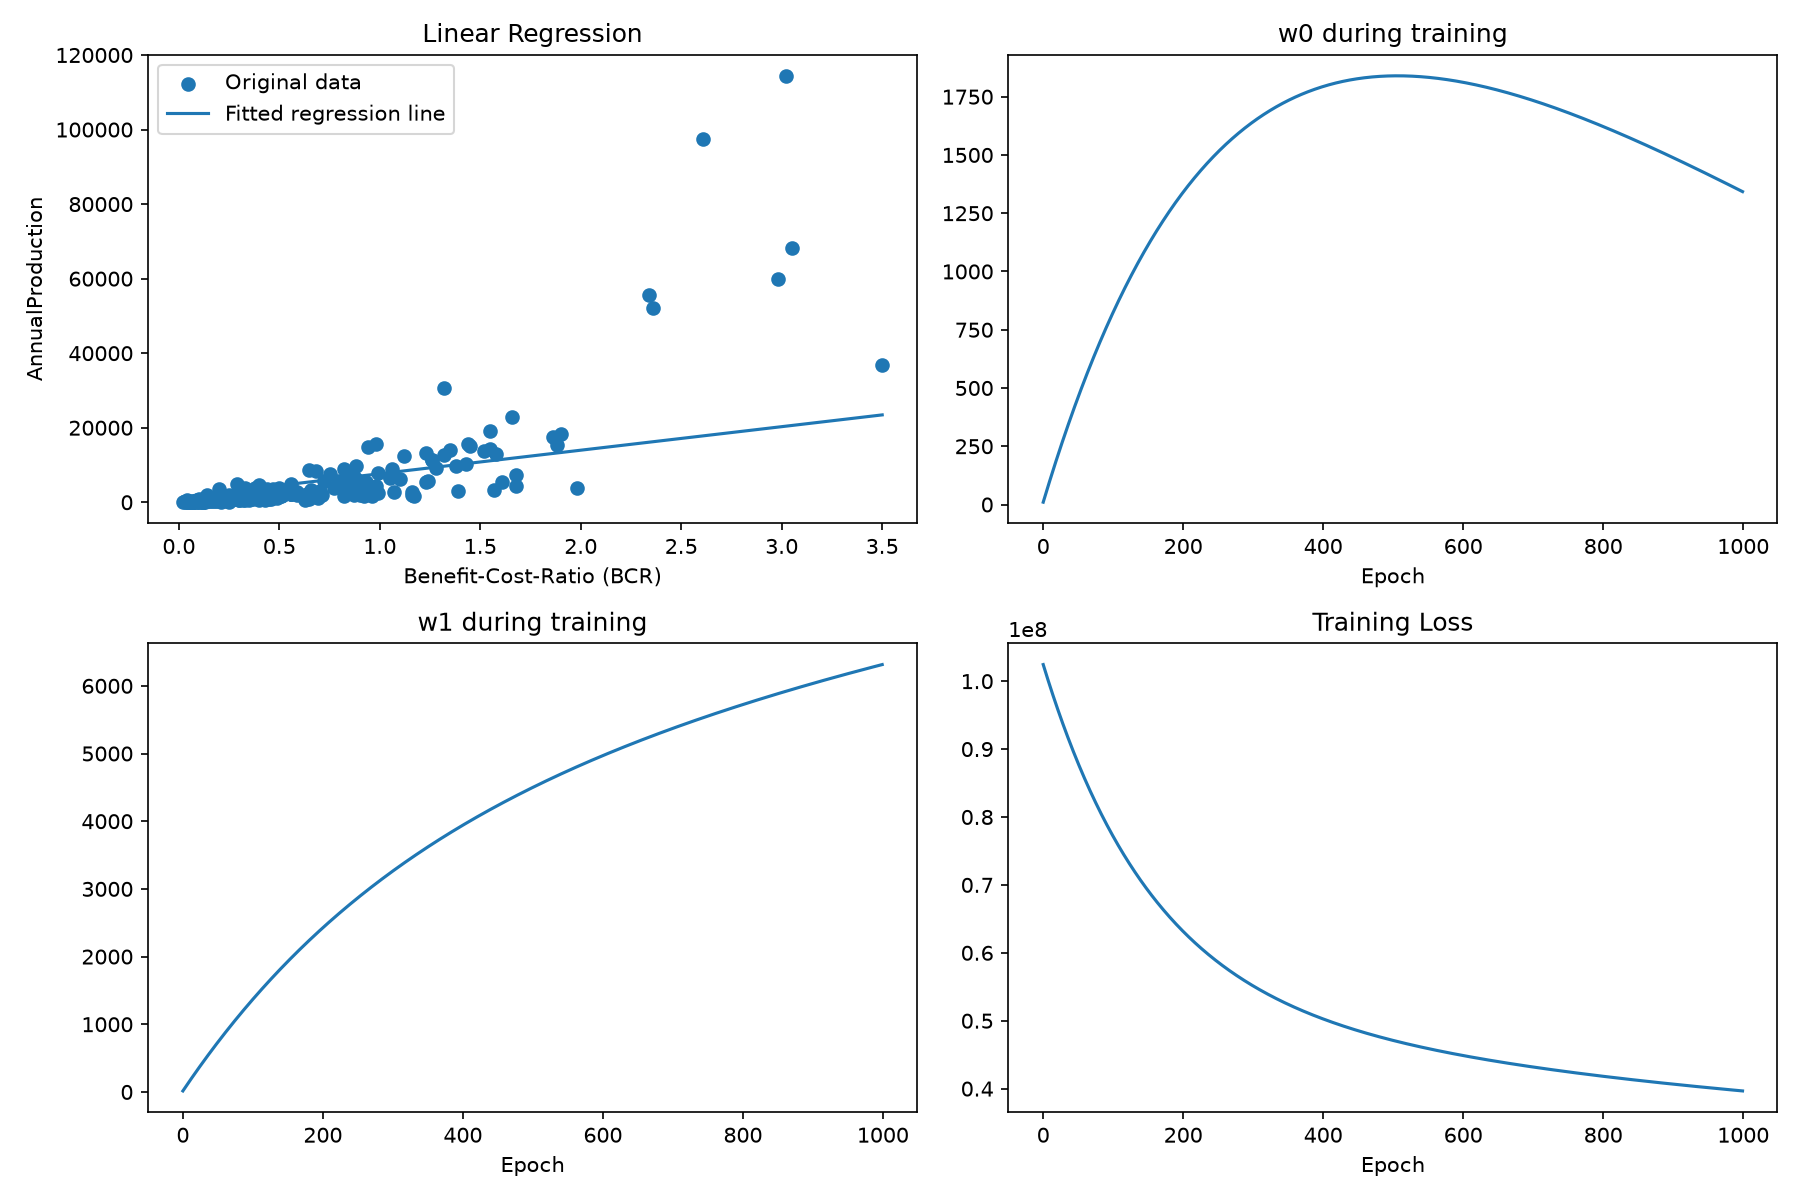

In [9]:
from IPython.display import Image, display

display(Image(filename="analysis_plot.png"))